# GF(DR) fit: radiopyo versus the paper (Tonneau et al. 2025)

With `variable_GValues` on, radiopyo scales the Boscolo G-values by a dose-rate factor GF(DR) = a·DR$^b$. Two fits exist:

| fit | a | b | where |
| --- | --- | --- | --- |
| shipped by radiopyo | 0.972 | −0.1097 | `GValuesBoscolo._scale_factor`, a later fit on the whole Blain data set |
| printed in the paper | 0.982 | −0.09 | fig. 3B of Tonneau et al. 2025 |

`tonneau_2025_pmb.ipynb` reproduces the paper with the shipped fit (ADR 0009). This notebook re-runs the same grid with the paper's fit (`paper_runs.run_grid(gf_fit="paper")`) and compares the two runs with each other and with the values quoted in the paper. The question is how much of the gap to the paper the GF fit explains.

Both grids are golden data in `tests/golden/data/`: `paper_tonneau_2025.npz` (shipped fit) and `paper_tonneau_2025_paper_gf.npz` (paper fit), written by `tests/golden/record_golden.py --only paper paper-gf`. The scenario (tables 3 and 5, solver settings) is described in the reproduction notebook.

In [1]:
import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import colors

# True: re-run the grid with the paper's GF fit instead of loading the
# golden file, and report the gap to it (about 10 min with 8 workers)
RECOMPUTE = False
WORKERS = 8

HERE = Path.cwd().resolve()
ROOT = next(
    p for p in (HERE, *HERE.parents)
    if (p / "pyproject.toml").exists() and (p / "radiopyo").is_dir()
)
if importlib.util.find_spec("radiopyo") is None:  # not installed: repo copy
    sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples" / "tonneau_2025_pmb"))

import paper_runs as pr

DATA = ROOT / "tests" / "golden" / "data"
UHDR_LIMIT = 100.0  # Gy/s
FITS = {"radiopyo": "shipped fit", "paper": "paper fit"}
STYLE = {"radiopyo": {"ls": "-"}, "paper": {"ls": "--"}}

In [2]:
shipped = pr.load_grid(DATA / "paper_tonneau_2025.npz")
paper_gf = pr.load_grid(DATA / "paper_tonneau_2025_paper_gf.npz")
if RECOMPUTE:
    def progress(done: int, total: int) -> None:
        if done % 100 == 0 or done == total:
            print(f"{done}/{total} runs", flush=True)

    new = pr.run_grid(workers=WORKERS, progress=progress, gf_fit="paper")
    gaps = {
        key: float(np.max(np.abs(new[key] - paper_gf[key]) / np.maximum(np.abs(paper_gf[key]), 1e-12)))
        for key in pr.GRID_KEYS
    }
    display(pd.Series(gaps, name="max relative difference to the golden file").to_frame())
    paper_gf = new
GRIDS = {"radiopyo": shipped, "paper": paper_gf}

DR, PO2, TS_DR, TIME = shipped["dose_rates"], shipped["po2"], shipped["ts_dose_rates"], shipped["time"]


def fmt_dr(dose_rate: float) -> str:
    exp = int(np.floor(np.log10(dose_rate) + 1e-9))
    if -1 <= exp <= 1:
        return f"{dose_rate:g}"
    mant = dose_rate / 10.0**exp
    return ("" if np.isclose(mant, 1.0) else f"{mant:g}x") + f"10$^{{{exp}}}$"

## The two fits

Both fits cross near 1 Gy/s. Below it the shipped fit is slightly higher; above it, the paper's fit is higher, by up to 39 % at 10$^7$ Gy/s (the shipped fit is 28 % lower). The CDR range of the paper (0.1–50 Gy/s) sees at most a few percent; the UHDR range sees most of the difference.

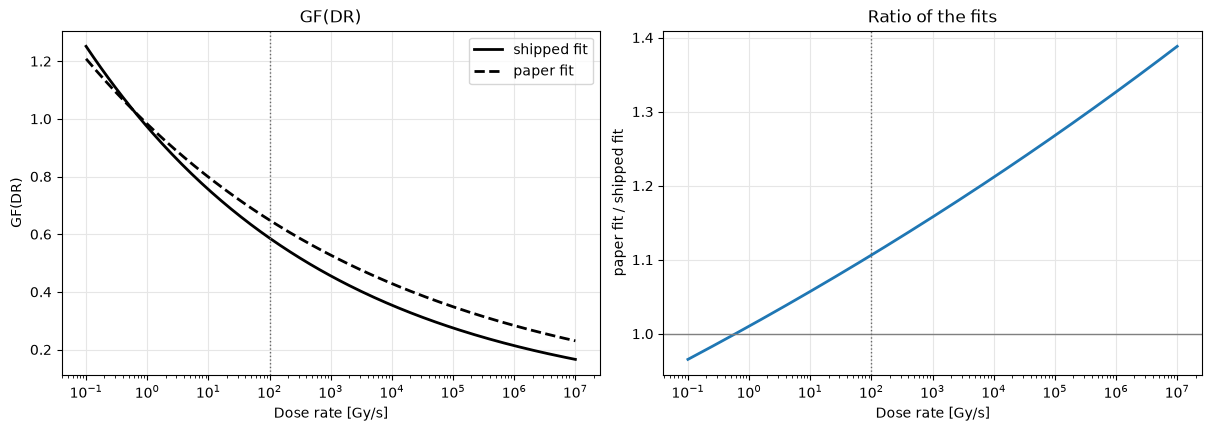

,radiopyo,paper,ratio
dose rate [Gy/s],,,
0.1,1.251,1.208,0.965
1,0.972,0.982,1.010
10,0.755,0.798,1.057
50,0.633,0.691,1.091
100,0.586,0.649,1.106
1000,0.456,0.527,1.158
10000,0.354,0.429,1.211
100000,0.275,0.348,1.268
1e+06,0.213,0.283,1.327


In [3]:
dr_line = np.logspace(-1, 7, 200)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for fit, label in FITS.items():
    ax1.plot(dr_line, pr.gf_factor(dr_line, fit), color="k", lw=2, label=label, **STYLE[fit])
ax1.set(xscale="log", xlabel="Dose rate [Gy/s]", ylabel="GF(DR)", title="GF(DR)")
ax1.legend()
ratio = pr.gf_factor(dr_line, "paper") / pr.gf_factor(dr_line, "radiopyo")
ax2.plot(dr_line, ratio, color="C0", lw=2)
ax2.axhline(1.0, color="0.5", lw=1)
ax2.set(xscale="log", xlabel="Dose rate [Gy/s]", ylabel="paper fit / shipped fit",
        title="Ratio of the fits")
for ax in (ax1, ax2):
    ax.axvline(UHDR_LIMIT, ls=":", color="0.4", lw=1)
    ax.grid(color="0.9")
plt.show()

pd.DataFrame(
    {fit: pr.gf_factor(TS_DR, fit) for fit in FITS},
    index=pd.Index(TS_DR, name="dose rate [Gy/s]"),
).assign(ratio=lambda d: d["paper"] / d["radiopyo"]).style.format("{:.3f}").format_index("{:g}")

## Values quoted in the paper

Same rows as the reproduction notebook, with both fits. Informational only.

In [4]:
rows = {fit: pr.quoted_values(grid, UHDR_LIMIT) for fit, grid in GRIDS.items()}
table = pd.DataFrame(
    [
        (q, cond, ref, a[3], b[3], src)
        for (q, cond, ref, _, src), a, b in zip(rows["radiopyo"], rows["radiopyo"], rows["paper"])
    ],
    columns=["quantity", "condition", "paper", "shipped fit", "paper fit", "source"],
)
table["shipped fit vs paper"] = table["shipped fit"] / table["paper"] - 1.0
table["paper fit vs paper"] = table["paper fit"] / table["paper"] - 1.0
table.style.format(
    {"paper": "{:.3g}", "shipped fit": "{:.3g}", "paper fit": "{:.3g}",
     "shipped fit vs paper": "{:+.0%}", "paper fit vs paper": "{:+.0%}"}
).hide(axis="index")

quantity,condition,paper,shipped fit,paper fit,source,shipped fit vs paper,paper fit vs paper
final H2O2 [µM],"1 % pO2, 1e2 Gy/s",2.2,2.12,2.35,"§3.3, fig. 7B",-3%,+7%
final H2O2 [µM],"1 % pO2, 1e4 Gy/s",2.45,2.36,2.88,"§3.3, fig. 7B",-4%,+18%
final H2O2 [µM],"1 % pO2, 1e7 Gy/s",1.25,1.15,1.61,"§3.3, fig. 7B",-8%,+29%
final H2O2 [µM],"5 % pO2, 1e2 Gy/s",1.75,1.69,1.87,"§3.3 (1.7-1.8), fig. 7D",-3%,+7%
final H2O2 [µM],"5 % pO2, 1e7 Gy/s",1.1,1.05,1.49,"§3.3, fig. 7D",-5%,+35%
"final H2O2 [µM], CDR min",1 % pO2,2,1.94,2.04,§3.3 (2.0-2.7),-3%,+2%
"final H2O2 [µM], CDR max",1 % pO2,2.7,2.48,2.41,§3.3 (2.0-2.7),-8%,-11%
"final H2O2 [µM], CDR min",5 % pO2,1.7,1.73,1.88,§3.3 (1.7-3.3),+2%,+11%
"final H2O2 [µM], CDR max",5 % pO2,3.3,3.06,2.96,§3.3 (1.7-3.3),-7%,-10%
"ΔO2 at 500 s [µM], CDR min",1 and 5 % pO2,0.8,0.57,0.623,§3.2.1 (0.8-1.2),-29%,-22%


## Final H$_2$O$_2$ and minimum pH versus dose rate

30 Gy, hypoxia (1 %) and physioxia (5 %). Solid: shipped fit; dashed: paper fit; crosses: values quoted in the paper text (§3.3, §4).

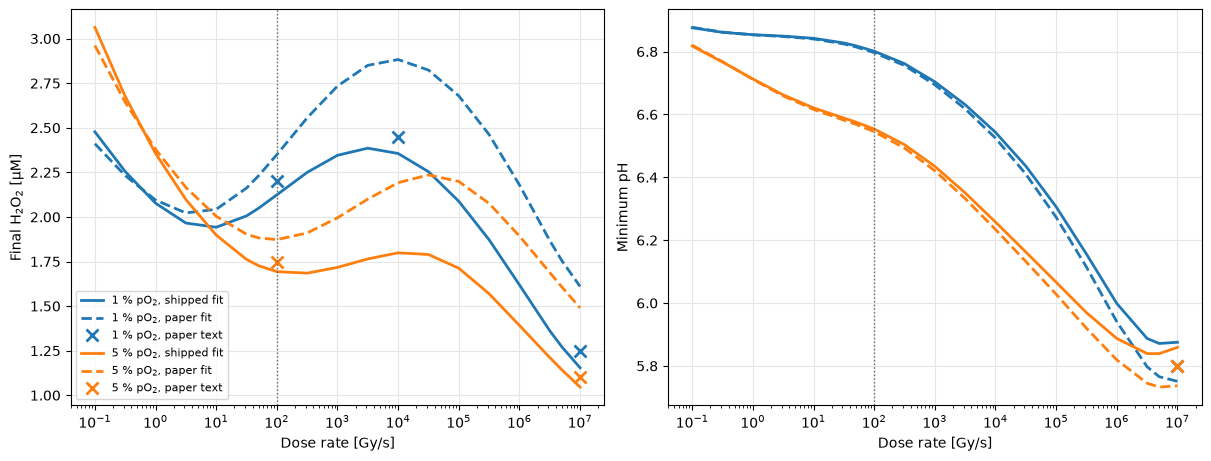

In [5]:
QUOTED_H2O2 = {1.0: {1e2: 2.2, 1e4: 2.45, 1e7: 1.25}, 5.0: {1e2: 1.75, 1e7: 1.1}}
QUOTED_PH = {1.0: {1e7: 5.8}, 5.0: {1e7: 5.8}}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, key, ylabel, quoted in (
    (axes[0], "h2o2_final", "Final H$_2$O$_2$ [µM]", QUOTED_H2O2),
    (axes[1], "ph_min", "Minimum pH", QUOTED_PH),
):
    for c, po2 in enumerate((1.0, 5.0)):
        j = pr.index_of(PO2, po2)
        for fit, grid in GRIDS.items():
            ax.plot(DR, grid[key][:, j, -1], color=f"C{c}", lw=2, **STYLE[fit],
                    label=f"{po2:g} % pO$_2$, {FITS[fit]}")
        q = quoted[po2]
        ax.plot(list(q), list(q.values()), "x", color=f"C{c}", ms=9, mew=2,
                label=f"{po2:g} % pO$_2$, paper text")
    ax.axvline(UHDR_LIMIT, ls=":", color="0.4", lw=1)
    ax.set(xscale="log", xlabel="Dose rate [Gy/s]", ylabel=ylabel)
    ax.grid(color="0.9")
axes[0].legend(fontsize=8)
plt.show()

## Time evolution

30 Gy, four dose rates of table 5. Solid: shipped fit; dashed: paper fit.

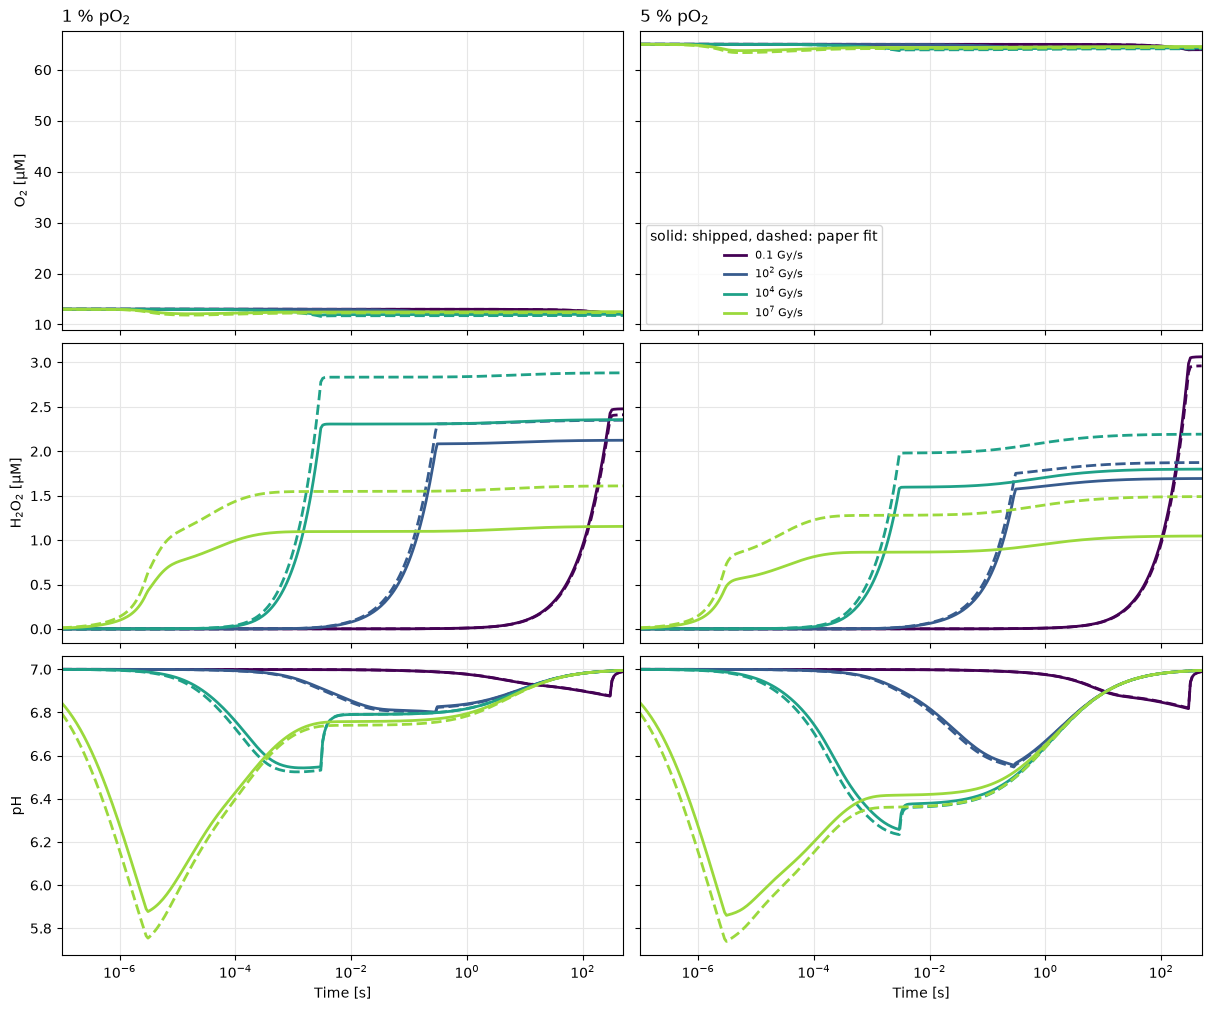

In [6]:
TS_SHOW = (0.1, 1e2, 1e4, 1e7)
SERIES = (("ts_o2", "O$_2$ [µM]"), ("ts_h2o2", "H$_2$O$_2$ [µM]"), ("ts_ph", "pH"))
shades = plt.get_cmap("viridis")(np.linspace(0.0, 0.85, len(TS_SHOW)))
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True, sharey="row", constrained_layout=True)
for b, po2 in enumerate(shipped["ts_po2"]):
    for r, (key, ylabel) in enumerate(SERIES):
        ax = axes[r, b]
        for dr, shade in zip(TS_SHOW, shades):
            a = pr.index_of(TS_DR, dr)
            for fit, grid in GRIDS.items():
                ax.plot(TIME, grid[key][a, b], color=shade, lw=2, **STYLE[fit],
                        label=f"{fmt_dr(dr)} Gy/s" if fit == "radiopyo" else None)
        ax.set_xscale("log")
        ax.set_xlim(TIME[0], TIME[-1])
        ax.grid(color="0.9")
        if b == 0:
            ax.set_ylabel(ylabel)
        if r == 0:
            ax.set_title(f"{po2:g} % pO$_2$", loc="left")
        if r == 2:
            ax.set_xlabel("Time [s]")
axes[0, 1].legend(title="solid: shipped, dashed: paper fit", fontsize=8)
plt.show()

## Maps: effect of the fit

Top: ΔO$_2$ at 500 s and net H$_2$O$_2$ yield with the paper's fit (paper figs 5 and 8). Bottom: relative change from the shipped fit, (paper fit − shipped fit) / shipped fit. The net yield is near zero in anoxia at CDR, so its relative change there is masked (|yield| < 0.05 #/100 eV with the shipped fit).

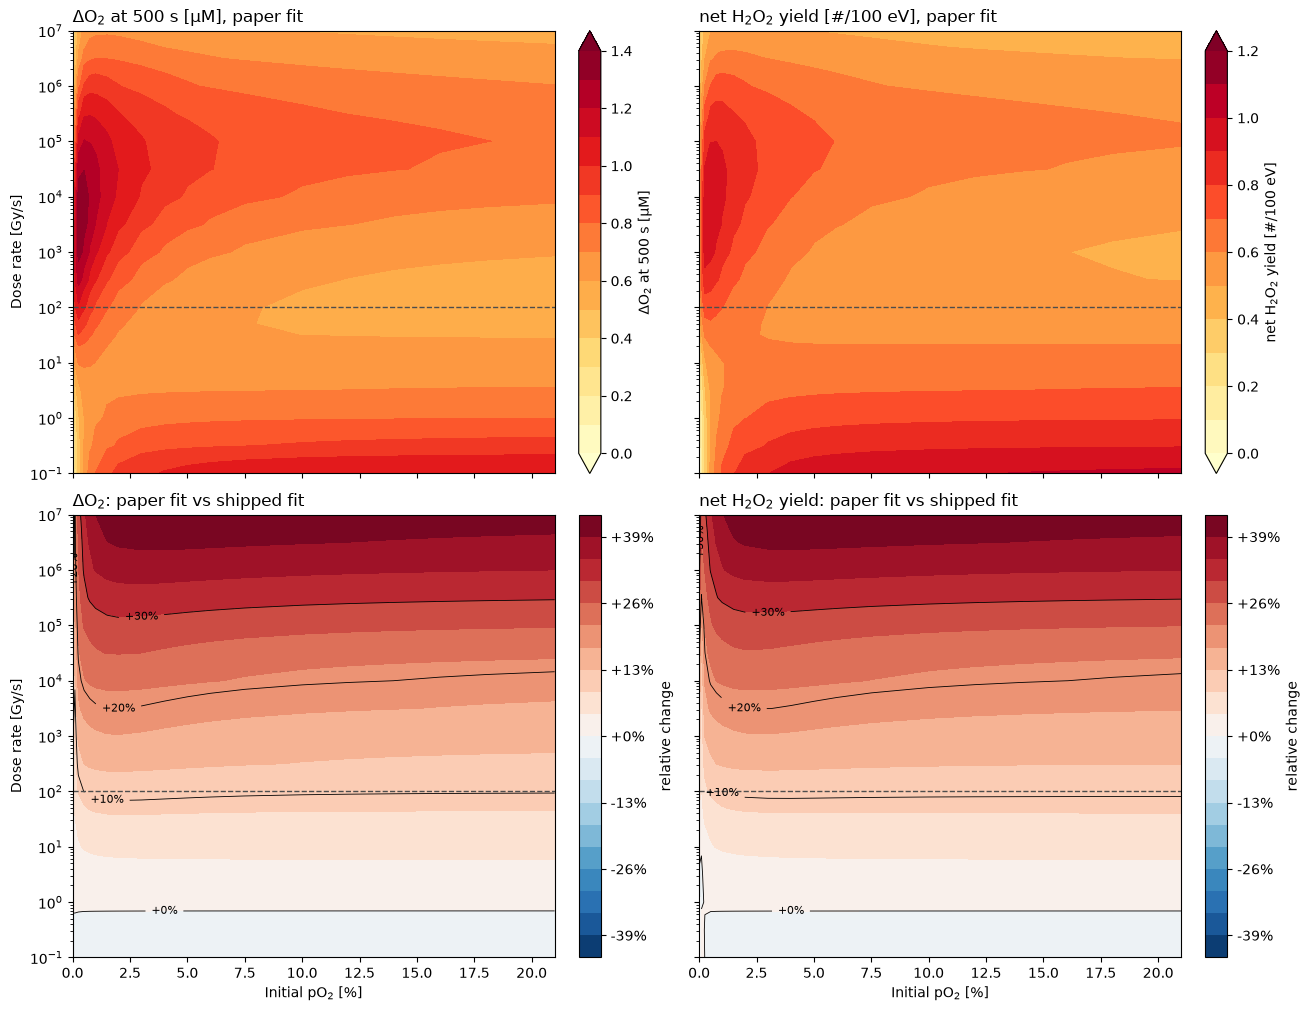

In [7]:
def maps(grid):
    return pr.delta_o2(grid), pr.net_yield_map(grid)


(d_o2_s, ny_s), (d_o2_p, ny_p) = maps(shipped), maps(paper_gf)
X, Y = np.meshgrid(PO2, DR)
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True, constrained_layout=True)
for c, (z, levels, label) in enumerate((
    (d_o2_p, np.linspace(0.0, 1.4, 15), "ΔO$_2$ at 500 s [µM]"),
    (ny_p, np.linspace(0.0, 1.2, 13), "net H$_2$O$_2$ yield [#/100 eV]"),
)):
    ax = axes[0, c]
    cf = ax.contourf(X, Y, z, levels=levels, cmap="YlOrRd", extend="both")
    fig.colorbar(cf, ax=ax, label=label)
    ax.set_title(f"{label}, paper fit", loc="left")

rel = {
    "ΔO$_2$": d_o2_p / d_o2_s - 1.0,
    "net H$_2$O$_2$ yield": np.where(np.abs(ny_s) > 0.05, ny_p / np.where(ny_s == 0, 1, ny_s) - 1.0, np.nan),
}
lim = np.nanmax([np.nanmax(np.abs(v)) for v in rel.values()])
norm = colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
for c, (name, z) in enumerate(rel.items()):
    ax = axes[1, c]
    cf = ax.contourf(X, Y, z, levels=np.linspace(-lim, lim, 21), cmap="RdBu_r", norm=norm)
    cs = ax.contour(X, Y, z, levels=[-0.2, -0.1, 0.0, 0.1, 0.2, 0.3], colors="k", linewidths=0.6)
    ax.clabel(cs, fmt=lambda v: f"{v:+.0%}", fontsize=8)
    fig.colorbar(cf, ax=ax, label="relative change", format=lambda v, _: f"{v:+.0%}")
    ax.set_title(f"{name}: paper fit vs shipped fit", loc="left")
for ax in axes.flat:
    ax.set_yscale("log")
    ax.axhline(UHDR_LIMIT, ls="--", color="0.3", lw=1)
for ax in axes[1]:
    ax.set_xlabel("Initial pO$_2$ [%]")
for ax in axes[:, 0]:
    ax.set_ylabel("Dose rate [Gy/s]")
plt.show()

## Gross H$_2$O$_2$ and O$_2$ production / consumption

30 Gy, versus initial pO$_2$ (bar points of figs 6 and 9). Solid: shipped fit; dashed: paper fit.

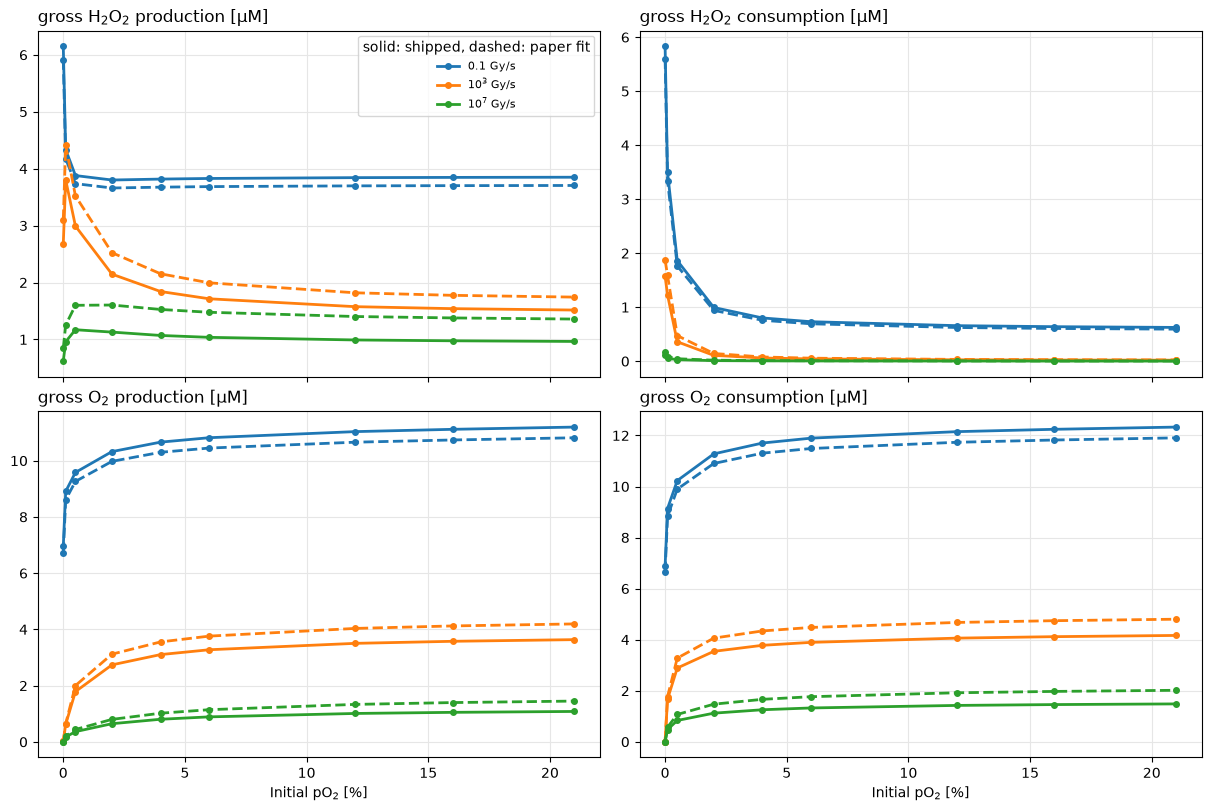

In [8]:
BAR_DR = (0.1, 1e3, 1e7)
bar_j = [pr.index_of(PO2, p) for p in pr.BAR_PO2]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, constrained_layout=True)
for r, species in enumerate(("h2o2", "o2")):
    for c, kind in enumerate(("production", "consumption")):
        ax = axes[r, c]
        for k, dr in enumerate(BAR_DR):
            i = pr.index_of(DR, dr)
            for fit, grid in GRIDS.items():
                ax.plot(pr.BAR_PO2, grid[f"{species}_{kind}"][i, bar_j], "o", color=f"C{k}",
                        lw=2, ms=4, **STYLE[fit],
                        label=f"{fmt_dr(dr)} Gy/s" if fit == "radiopyo" else None)
        name = "H$_2$O$_2$" if species == "h2o2" else "O$_2$"
        ax.set_title(f"gross {name} {kind} [µM]", loc="left")
        ax.grid(color="0.9")
        if r == 1:
            ax.set_xlabel("Initial pO$_2$ [%]")
axes[0, 0].legend(title="solid: shipped, dashed: paper fit", fontsize=8)
plt.show()

## Reading the comparison

- **The paper's fit does not close the gap: it overshoots at UHDR.** With it, the UHDR values quoted in the paper are exceeded by 18 to 35 % (final H$_2$O$_2$ at 10$^4$ and 10$^7$ Gy/s), while the shipped fit stays 4 to 8 % below them. At 10$^2$ Gy/s the two bracket the paper (−3 % and +7 %). The minimum pH at 10$^7$ Gy/s is 5.88 with the shipped fit and 5.75 with the paper's, against 5.8 quoted.
- **At CDR the fit hardly matters.** The two fits are within 4 % between 0.1 and 50 Gy/s, and so are the results. The CDR gaps (ΔO$_2$ range 0.57–1.06 µM against 0.8–1.2 µM, gross O$_2$ yields and net H$_2$O$_2$ production 7 to 11 % low) are of the same size with either fit. They come from something other than GF(DR).
- **The effect of the fit grows with the dose rate and barely depends on pO$_2$** (maps above): about +10 % at 10$^2$ Gy/s, +20 % at 10$^4$ Gy/s and +39 % at 10$^7$ Gy/s on ΔO$_2$ and on the net H$_2$O$_2$ yield, which follow the ratio of the two fits. The shapes do not change: the hot spot at 10$^3$–10$^5$ Gy/s and low pO$_2$ stays where it is, it is only stronger.
- The UHDR values of the paper therefore look closer to the shipped fit than to the one printed in fig. 3B, and the author's original results confirm it: the values quoted in the text come from runs with the shipped fit, at LET 0.56 keV/µm and with the config `CONFIG_PAPER_01.toml`; the printed fit belongs to a later rerun at LET 1.17 keV/µm. The `"original"` scenario of `tonneau_2025_pmb.ipynb` reproduces the quoted values to about 1 %, which supports keeping the shipped fit (ADR 0009).